# Causal Cafe Lab - Answer Notebook (facilitator only)
Generated by scripts/build_answer_notebook.py from workshop.py: the four TODOs
are filled in, nothing else changes. Do not put this file on `main`.

## Workshop background
A beverage chain sends coupons to customers predicted to buy. The campaign
report counts recipient purchases, but some customers would have bought
without a coupon. The business question is how much purchasing the coupons add.

In this lab, you will estimate coupon uplift, evaluate its ranking on a
randomized pilot, and select customers within a 2,500 Growth Budget.
Selection uses estimated additional margin after coupon costs.
The data are synthetic teaching data.

Run the cells in order. Complete the four TODO functions before continuing:
`naive_observed_difference`, `fit_t_learner`, `qini_curve`, and
`build_customer_scores`. In Colab, save an editable copy first.

## Setup
The following cell downloads the public repository if the helpers are
missing and sets the working directory and Python import path.
The **working directory** is the base folder for relative file paths.

In [ ]:
# Setup: fetch the workshop files when they are not already next to this notebook.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/tjunjie1408/cafe_lab.git"

if not Path("src/workshop_data.py").exists():
    if not Path("cafe_lab").exists():
        subprocess.run(
            ["git", "clone", "--depth", "1", "--branch", "main", REPO_URL, "cafe_lab"],
            check=True,
        )
    os.chdir("cafe_lab")
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))  # so `import src` finds the downloaded helpers
print("Working directory:", Path.cwd())

Subsequent cells load data and save artifacts relative to the printed
working directory.

### Load the customer data
`load_observed_data()` loads the historical campaign into `observed`, a
pandas **DataFrame** (a table with named columns). Each row is one customer;
`head()` displays the first five rows.

The imports provide the estimators, data helpers, policy and plotting
functions. `FEATURES` lists the seven pre-coupon model inputs. An **outcome**
is the quantity being predicted.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

from src.workshop_data import (
    FEATURES, ARTIFACT_COLUMNS, GROWTH_BUDGET,
    load_observed_data, load_pilot_data, split_train_test,
)
from src.evaluation import qini_coefficient
from src.policy import select_under_budget
from src.predictive import fit_purchase_baseline
from src.causal_models import fit_s_learner, predict_outcomes, predict_uplift, save_bundle, load_bundle
from src.visualisation import (
    plot_coupon_campaign_summary,
    plot_coupon_audience,
    plot_budget_curve,
    plot_causal_dag,
    plot_confounding_overlap,
    plot_effect_summary,
    plot_model_check,
    plot_qini_curves,
    plot_t_learner_schematic,
    plot_targeting_map,
    plot_uplift_archetypes,
    plot_uplift_distribution,
    plot_workshop_roadmap,
)

observed = load_observed_data()
observed.head()

The leftmost index is a pandas row label; `customer_id` identifies the
customer. The columns have the following roles:

| Column | Meaning and unit | Role in the notebook |
| --- | --- | --- |
| `customer_id` | Customer identifier | Keeps scores aligned; not a predictor |
| `days_since_last_purchase` | Days since the last purchase | Pre-coupon history feature |
| `orders_30d` | Number of orders in the preceding 30 days | Pre-coupon history feature |
| `app_sessions_30d` | Number of app sessions in the preceding 30 days | Pre-coupon history feature |
| `average_order_value` | Historical money per order | Pre-coupon history feature |
| `loyalty_score` | Loyalty score | Pre-coupon history feature |
| `price_sensitivity` | Price-response score | Pre-coupon response feature |
| `offer_affinity` | Offer-affinity score | Pre-coupon response feature |
| `coupon_sent` | 1 = coupon assigned; 0 = no coupon | Treatment, written as T |
| `purchased_7d` | 1 = purchased within seven days; 0 = did not | Outcome, written as Y |
| `expected_order_margin` | Expected margin per additional order | Value input for the policy |
| `expected_coupon_cost` | Expected cost per coupon assignment | Cost input for the policy |

**Pre-coupon** means measured before assignment. A response or loyalty score
is a feature value, not automatically a purchase probability. Sending a
coupon and redeeming a coupon are different events: T records sending.

### Workflow
The diagram summarizes the five tasks. A **policy** converts scores and a
budget into actions, such as sending a coupon.

In [ ]:
plot_workshop_roadmap()

Purchase prediction estimates who will buy. Causal estimation estimates
the change due to the coupon. The policy uses that change, margin and cost
to select customers. Arrows indicate workflow steps, not measured effects.

## Campaign overview
Summarize campaign size, purchase rates and expected costs. For a binary
column, the **mean** equals the fraction of rows with value 1.
`len()` counts rows, `.sum()` adds values, and `.round(3)` sets display
precision. The output is a pandas **Series** of labeled values.

In [ ]:
overview = pd.Series(
    {
        "customers": len(observed),
        "share sent a coupon": observed["coupon_sent"].mean(),
        "7-day purchase rate": observed["purchased_7d"].mean(),
        "mean order margin": observed["expected_order_margin"].mean(),
        "mean coupon cost": observed["expected_coupon_cost"].mean(),
        "cost to coupon everyone": observed["expected_coupon_cost"].sum(),
        "Growth Budget": GROWTH_BUDGET,
    }
).round(3)
overview

Output definitions:

| Output row | What it summarizes |
| --- | --- |
| `customers` | Number of customer rows |
| `share sent a coupon` | Recipients divided by all customers |
| `7-day purchase rate` | Buyers divided by all customers, across both arms |
| `mean order margin` | Average supplied expected margin per additional order |
| `mean coupon cost` | Average supplied expected cost per coupon assignment |
| `cost to coupon everyone` | Sum of expected coupon costs for all customers |
| `Growth Budget` | Expected-cost limit used by the policy |

Shares are displayed as decimals, so 0.30 corresponds to 30%. Compare the
total expected cost with the budget to see why the notebook needs a selection
rule. Margin is money remaining from an order after ordinary order costs;
it is not the same quantity as order revenue.

### Describe the feature distributions
`observed[FEATURES].describe().T` summarizes each input feature on one row.
`.round(2)` sets display precision. A **distribution** describes how values
vary across customers; these summaries describe features, not coupon effects.

In [ ]:
observed[FEATURES].describe().T.round(2)

Each row is a feature. The columns summarize its observed distribution:

| Column | Statistical meaning |
| --- | --- |
| `count` | Number of non-missing values in that feature |
| `mean` | Arithmetic average |
| `std` | Sample standard deviation: spread around the mean, in the feature's units |
| `min` | Smallest observed value |
| `25%` | First quartile: the 25th percentile |
| `50%` | Median: the middle percentile |
| `75%` | Third quartile: the 75th percentile |
| `max` | Largest observed value |

The variance is the squared-spread quantity; its square root is the standard
deviation. Larger `std` means more feature variation, but days and money use
different scales. The median splits a distribution in half; a mean far from
the median can indicate an asymmetric distribution. A `count` below the
overview's customer total indicates missing values for that feature.

### Build the purchase-probability baseline
The **baseline** model estimates purchase probability and stores it in
`purchase_probability`. Probabilities range from 0 to 1; the observed
purchase outcome is either 0 or 1.

In [ ]:
observed["purchase_probability"] = fit_purchase_baseline(observed)
observed[["customer_id", "purchase_probability", "coupon_sent", "purchased_7d"]].head()

The output contains a model estimate and two observed events:

| Column | Question it answers |
| --- | --- |
| `customer_id` | Which customer is this? |
| `purchase_probability` | How likely does the baseline think this customer is to buy? |
| `coupon_sent` | Was this customer assigned a coupon historically? |
| `purchased_7d` | Did this customer actually buy within seven days? |

A high purchase score can occur with an observed non-purchase; a probability
is not a promise. This table does not show two treatment-setting predictions,
so its purchase score alone does not tell us how much a coupon helps.

### Compare the four response archetypes
The grid shows four conceptual response patterns, or **archetypes**, under
coupon and no-coupon settings. The unobserved setting is a
**counterfactual**. Only one outcome is observed per customer occasion.

In [ ]:
plot_uplift_archetypes()

The four conceptual response patterns are:

| Archetype | Without coupon | With coupon |
| --- | --- | --- |
| Persuadable | Does not buy | Buys |
| Likely purchaser | Buys | Buys |
| Unlikely purchaser | Does not buy | Does not buy |
| Negative responder | Buys | Does not buy |

These are conceptual paired outcomes, not observed labels in the customer
table. Only one setting is observed per customer occasion. In particular,
being likely to buy does not distinguish a persuadable from someone who buys
either way. The later models estimate probability contrasts, not these known
personal labels.

## Task 1 - Interpret the campaign DAG
A **DAG** (directed acyclic graph) represents assumed causal relationships
without directed loops. Here X denotes pre-coupon features, T coupon
assignment, and Y purchasing. A **confounder** is a common cause of treatment
and outcome.

In [ ]:
plot_causal_dag()

Customer history points to both T and Y, creating the **backdoor path**
`T <- X -> Y`. This can associate coupons with purchases independently of
the coupon effect.

**Adjustment** uses pre-coupon features to compare similar customer profiles.
The purple box represents traits that may modify the response; the red box
marks post-coupon variables excluded from adjustment. The diagram states
identification assumptions, not measured coefficients or proof of an effect.

## Task 2 - Calculate the naive observed difference
Complete `naive_observed_difference(df)` to return the coupon group's
purchase rate minus the no-coupon group's rate as a float.

The **treated arm** is T=1; the **control arm** is T=0. Each rate is the
mean of that arm's binary outcomes, using its own customer count as the
denominator. **Naive** means no adjustment for customer history.

In [ ]:
def naive_observed_difference(df: pd.DataFrame) -> float:
    treated = df.loc[df["coupon_sent"] == 1, "purchased_7d"].mean()
    control = df.loc[df["coupon_sent"] == 0, "purchased_7d"].mean()
    return float(treated - control)


naive = naive_observed_difference(observed)
print("naive observed difference:", naive)

A positive difference means recipients purchased more often than
non-recipients; a negative difference means the reverse. A value of 0.10
is **10 percentage points**, not a 10% relative increase.

This observed difference is not automatically the **ATE** (average
treatment effect). The historical groups may have different customer histories.

### Compare pre-coupon feature means
The **standardized mean difference** (SMD) measures mean imbalance between
the historical treatment groups:

`SMD = (treated mean - control mean) / sqrt((treated variance + control variance) / 2)`

Dividing by the pooled standard deviation expresses the difference on a
common scale instead of days, money or score units.

In [ ]:
treated_x = observed.loc[observed["coupon_sent"] == 1, FEATURES]
control_x = observed.loc[observed["coupon_sent"] == 0, FEATURES]
balance = pd.DataFrame({"no coupon": control_x.mean(), "coupon": treated_x.mean()})
balance["SMD"] = (treated_x.mean() - control_x.mean()) / np.sqrt(
    (treated_x.var() + control_x.var()) / 2
)
balance.round(3)

Each row compares one feature. `no coupon` and `coupon` are the group
means; `SMD` expresses their gap on the common scale. Positive means a larger
treated mean, and negative means a smaller one.

Interpret the feature as well as the sign: fewer `days_since_last_purchase`
means a more recent buyer, whereas more `orders_30d` means more orders.
An SMD near zero means similar feature means, not identical distributions
or proof that all relevant common causes were recorded.

### Estimate propensity and inspect overlap
This logistic model predicts coupon assignment T. Its **propensity score**
estimates the probability of receiving a coupon given the features.
`predict_proba(...)[:, 1]` selects the class-1 probability.

**Overlap** requires both treatment groups to have support for relevant
customer profiles. The printed range and tail share summarize fitted propensities.

In [ ]:
propensity_model = LogisticRegression(max_iter=2000).fit(observed[FEATURES], observed["coupon_sent"])
propensity = propensity_model.predict_proba(observed[FEATURES])[:, 1]
print(f"propensity range:           {propensity.min():.2f} - {propensity.max():.2f}")
print(f"share outside [0.05, 0.95]: {((propensity < 0.05) | (propensity > 0.95)).mean():.1%}")
plot_confounding_overlap(balance["SMD"], propensity, observed["coupon_sent"])

The printout gives the fitted propensity range and the fraction outside
[0.05, 0.95]. These thresholds are diagnostic reference values.

- **Left:** larger absolute SMD indicates greater mean imbalance. Lines at
  +/-0.1 are reference flags.
- **Right:** the histograms compare propensity support. The y-axis is
  **density**; bin area represents a share, not a customer count.

Sparse or separated support warns of extrapolation for poorly represented
profiles. Fitted overlap does not rule out unmeasured confounding.

## Task 3 - Split training and test customers
The **training set** is used for fitting; the **held-out test set** is used
to evaluate predictions. The helper uses a 70/30 split, stratified on
`coupon_sent` to preserve representation of both arms.

In [ ]:
train, test = split_train_test(observed)
print(f"train: {len(train):,} customers · test: {len(test):,} customers")

The printed counts give the training and test sizes. Model fitting uses
`train`; purchase AUC evaluation uses `test`. Splitting does not change
the historical treatment assignments.

### T-Learner
The T-Learner fits **two outcome models**. For the same feature profile x,
`mu0(x)` estimates purchase probability without a coupon and `mu1(x)`
estimates it with a coupon. Estimated **uplift** is `mu1(x) - mu0(x)`.

In [ ]:
plot_t_learner_schematic()

Both branches score the same customer features. The control prediction
is subtracted from the treated prediction to estimate **CATE** (conditional
average treatment effect): an average contrast for that feature profile.

The missing treatment setting is estimated from other customers under the
diagram's identification assumptions. This does not reveal an individual's
unobserved binary outcome. The train/test split precedes fitting.

### Fit, save and score the T-Learner
Complete `fit_t_learner` using **logistic regression**, a binary-outcome
classifier. Create a separate `make_model()` instance for each arm, fit it
on that arm's training rows, and return `(model_control, model_treated)`.
Reusing one instance would overwrite the first fit.

The prediction helper selects purchase probabilities with `[:, 1]`.
The code saves a **model bundle** containing fitted estimators and feature
information, reloads it, and scores held-out customers.

In [ ]:
def make_logistic():
    return LogisticRegression(max_iter=2000)


def fit_t_learner(train, features=FEATURES, make_model=make_logistic):
    treated = train[train["coupon_sent"] == 1]
    control = train[train["coupon_sent"] == 0]
    model_treated = make_model().fit(treated[features], treated["purchased_7d"])
    model_control = make_model().fit(control[features], control["purchased_7d"])
    return model_control, model_treated


def predict_t_learner(model_control, model_treated, score, features=FEATURES):
    mu0 = model_control.predict_proba(score[features])[:, 1]
    mu1 = model_treated.predict_proba(score[features])[:, 1]
    return mu0, mu1, mu1 - mu0


def t_learner_uplift(train, score, features=FEATURES, make_model=make_logistic):
    model_control, model_treated = fit_t_learner(train, features, make_model)
    return predict_t_learner(model_control, model_treated, score, features)


model_control, model_treated = fit_t_learner(train)
model_path = save_bundle(
    {"kind": "t", "features": list(FEATURES),
     "model_control": model_control, "model_treated": model_treated},
    Path("artifacts/models/t_learner.joblib"), training_rows=len(train), split_seed=42,
)
restored = load_bundle(model_path)
model_control, model_treated = restored["model_control"], restored["model_treated"]
mu0, mu1, uplift = predict_t_learner(model_control, model_treated, test)
plot_uplift_distribution(uplift)

The histogram shows estimated uplift among test customers. The x-axis
is a probability change; bar height counts customers. Zero separates
positive and negative estimates.

Variation in estimated effects is called **heterogeneity**. The spread also
includes model error; a negative estimate is not a verified personal response
type. Unexpected signs may indicate reversed model order or subtraction.

### Calculate break-even and summarize uplift
**Break-even** occurs when expected added margin equals expected coupon
cost. For positive margin, the required uplift is `cost / margin`.
The mean of `(uplift > break_even)` is the share of test customers whose
estimates exceed their individual thresholds.

In [ ]:
break_even = (test["expected_coupon_cost"] / test["expected_order_margin"]).to_numpy()
print(f"mean uplift:            {uplift.mean():+.3f}")
print(f"share with uplift < 0:  {(uplift < 0).mean():.1%}")
print(f"share above break-even: {(uplift > break_even).mean():.1%}")

The output summarizes test customers:

| Line | Meaning |
| --- | --- |
| `mean uplift` | Average estimated probability change over test customers |
| `share with uplift < 0` | Fraction with a negative estimated change |
| `share above break-even` | Fraction whose uplift exceeds their own cost/margin threshold |

The first is a probability difference; the last two are percentages of
customers. Positive uplift can still be below break-even, so a positive
coupon response need not imply positive estimated profit.

### Check held-out purchase AUC
**ROC AUC** measures purchase ranking: the probability that a randomly
chosen buyer ranks above a non-buyer, with half credit for ties. It is the
area under the receiver operating characteristic curve.

`held_out_auc` evaluates each model on held-out customers in its observed
arm. `~treated` selects control rows.

In [ ]:
def held_out_auc(test, mu0, mu1):
    treated = test["coupon_sent"].to_numpy() == 1
    y = test["purchased_7d"].to_numpy()
    return roc_auc_score(y[~treated], mu0[~treated]), roc_auc_score(y[treated], mu1[treated])


print("logistic  AUC mu0 %.3f · mu1 %.3f" % held_out_auc(test, mu0, mu1))

`mu0` reports purchase AUC among controls; `mu1` reports it among coupon
recipients. An AUC of 0.5 indicates chance ordering and 1 indicates perfect
ordering. AUC is not classification accuracy or a check of probability calibration.

### Repeat the comparison with gradient boosting
**Gradient boosting** combines successive fitted trees to improve outcome
prediction. This histogram-based classifier can represent nonlinear feature
relationships. Repeat fitting, saving, reloading and prediction with the
same training arms and test split.

In [ ]:
def make_boosting():
    return HistGradientBoostingClassifier(random_state=0)


gb_control, gb_treated = fit_t_learner(train, make_model=make_boosting)
gb_path = save_bundle(
    {"kind": "t", "features": list(FEATURES),
     "model_control": gb_control, "model_treated": gb_treated},
    Path("artifacts/models/t_learner_boosting.joblib"), training_rows=len(train), split_seed=42,
)
boosting_bundle = load_bundle(gb_path)
mu0_gb, mu1_gb = predict_outcomes(boosting_bundle, test)
uplift_gb = mu1_gb - mu0_gb
print("boosting  AUC mu0 %.3f · mu1 %.3f" % held_out_auc(test, mu0_gb, mu1_gb))

Compare each AUC with the logistic model's value for the same held-out
arm. Higher AUC indicates better purchase ranking on this split.
The pilot also evaluates uplift ranking using `uplift_gb`.

### Compare the provided S-Learner
An **S-Learner** fits one model using features X and treatment T. This
implementation includes **interactions** (`X * T`) so feature relationships
can vary with treatment. It predicts each test row with T=0 and T=1.

In [ ]:
s_path = save_bundle(
    fit_s_learner(train, FEATURES), Path("artifacts/models/s_learner.joblib"),
    training_rows=len(train), split_seed=42,
)
s_bundle = load_bundle(s_path)
mu0_s, mu1_s = predict_outcomes(s_bundle, test)
print("S-Learner AUC mu0 %.3f · mu1 %.3f" % held_out_auc(test, mu0_s, mu1_s))

`mu0_s` and `mu1_s` come from the shared model under the two treatment
settings. AUC uses each row's observed arm. The difference between the two
predictions supplies the S-Learner's pilot uplift ranking.

## Task 4 - Build the randomized-pilot Qini curve
We have checked purchase predictions. The pilot gives us a comparison
for the uplift ordering. Its coupon assignments were randomized, so they
do not follow the old campaign's targeting rule. Score these customers with
the saved models while keeping their purchase outcomes out of fitting.

Complete `qini_curve(pilot, score)`. A **ranking** orders customers by score;
a **prefix** is the first k customers in that ordering. Keep score/row
alignment, sort highest first, and compute four cumulative counts:

| Count | What accumulates as the prefix grows |
| --- | --- |
| Treated count | Coupon-assigned customers |
| Control count | Non-assigned customers |
| Treated buyers | Customers with T=1 and Y=1 |
| Control buyers | Customers with T=0 and Y=1 |

Return `share = k / pilot_size` and
`gain = treated_buyers - control_buyers * treated_count / control_count`.
The ratio scales control buyers to the prefix's treated-group size. Guard
division by zero; a prefix without controls has no observed control rate.

In [ ]:
pilot = load_pilot_data()
print(f"pilot: {len(pilot):,} customers · coupon rate {pilot['coupon_sent'].mean():.1%}")


def qini_curve(pilot, score):
    order = np.argsort(-np.asarray(score))
    treated = pilot["coupon_sent"].to_numpy()[order]
    bought = pilot["purchased_7d"].to_numpy()[order]
    n_treated = np.cumsum(treated)
    n_control = np.cumsum(1 - treated)
    buyers_treated = np.cumsum(bought * treated)
    buyers_control = np.cumsum(bought * (1 - treated))
    scale = np.divide(n_treated, n_control, out=np.zeros(len(order)), where=n_control > 0)
    gain = buyers_treated - buyers_control * scale
    share = np.arange(1, len(order) + 1) / len(order)
    return pd.DataFrame({"share": share, "gain": gain})


baseline_model = LogisticRegression(max_iter=2000).fit(train[FEATURES], train["purchased_7d"])
curves = {
    "T-Learner, logistic": qini_curve(pilot, predict_uplift(restored, pilot)),
    "T-Learner, boosting": qini_curve(pilot, predict_uplift(boosting_bundle, pilot)),
    "S-Learner, logistic + interactions": qini_curve(pilot, predict_uplift(s_bundle, pilot)),
    "purchase probability (old AI)": qini_curve(pilot, baseline_model.predict_proba(pilot[FEATURES])[:, 1]),
}
plot_qini_curves(curves)

The printout reports pilot size and treatment share. The chart's x-axis
is the fraction included in score order. Its y-axis is cumulative estimated
additional purchases on the treated-group scale, not profit or probability.

The dashed **random reference** joins zero to full-pilot gain. The legend's
**Qini score** is this repository's mean curve height above that reference.
A higher early curve indicates gain concentrated near the top of the ranking.
Early prefixes can be noisy; small score differences do not establish a
reliable winner. Subsequent policy cells use the logistic T-Learner.

## Task 5 - Build the budget-constrained customer scores
Finance still needs a send list. Convert the estimated response into
money with `uplift * expected_order_margin - expected_coupon_cost`.
This is **expected incremental profit**: added margin relative to no coupon,
after the coupon's expected cost. "Expected" means an average planning value
over uncertain outcomes, rather than guaranteed cash from a customer.

Probability change times margin per added order gives money per assignment.
The supplied margin excludes the coupon charge; subtract expected cost once.
Pass profit, cost and `GROWTH_BUDGET` to `select_under_budget`. This **greedy**
rule tries positive-profit customers in descending order, skipping costs
that do not fit. Unequal costs mean it is a feasible heuristic, not a proven
optimal allocation. Preserve input row order and `ARTIFACT_COLUMNS`.

In [ ]:
def build_customer_scores(df, uplift):
    margin = df["expected_order_margin"].to_numpy()
    cost = df["expected_coupon_cost"].to_numpy()
    profit = uplift * margin - cost
    return pd.DataFrame(
        {
            "customer_id": df["customer_id"].to_numpy(),
            "purchase_probability": df["purchase_probability"].to_numpy(),
            "estimated_uplift": uplift,
            "expected_incremental_profit": profit,
            "recommended": select_under_budget(profit, cost, GROWTH_BUDGET),
        }
    )[ARTIFACT_COLUMNS]


uplift_all = predict_t_learner(model_control, model_treated, observed)[2]
scores = build_customer_scores(observed, uplift_all)
Path("artifacts").mkdir(parents=True, exist_ok=True)
scores.to_csv("artifacts/customer_scores.csv", index=False)
scores.head()

Each row now carries a proposed decision alongside its scores. The
same table is written to `artifacts/customer_scores.csv`:

| Column | Meaning | Unit or encoding |
| --- | --- | --- |
| `customer_id` | Original customer identifier | Identifier |
| `purchase_probability` | Provided purchase-baseline score | Probability |
| `estimated_uplift` | Predicted treated minus control purchase probability | Probability difference |
| `expected_incremental_profit` | Uplift times margin, minus expected cost | Money per assignment |
| `recommended` | Whether the budget rule selects the customer | 1 = select, 0 = do not select |

`head()` shows only the first five rows in input order, not the five best
customers. A non-selected customer can have positive estimated profit if
the available budget is insufficient.

### Verify saved-model predictions
**Serialization** saves fitted model objects to disk. Reloading restores
them without retraining. `assert_allclose` checks that restored uplift
matches the values used by the policy within a small tolerance.

In [ ]:
restored_uplift = predict_uplift(restored, observed)
np.testing.assert_allclose(restored_uplift, uplift_all, rtol=1e-12)
print(f"Saved and reloaded: {model_path} ({model_path.stat().st_size:,} bytes)")

A successful assertion confirms that the saved model reproduces the
policy predictions. The printout reports the file path and size in bytes.
This check does not evaluate causal accuracy or campaign returns.

### Summarize the selected policy
`chosen` is a **Boolean mask**: True for selected customers, False otherwise.
Its sum counts selections; `.loc[chosen, ...]` selects their values for
aggregation. The final mean uplift instead uses all scored customers.

In [ ]:
chosen = scores["recommended"] == 1
spend = observed.loc[chosen, "expected_coupon_cost"].sum()
print(f"customers recommended:        {chosen.sum():,}")
print(f"expected coupon spend:        {spend:,.2f} / {GROWTH_BUDGET:,.0f}")
print(f"expected incremental orders:  {scores.loc[chosen, 'estimated_uplift'].sum():,.1f}")
print(f"expected incremental profit:  {scores.loc[chosen, 'expected_incremental_profit'].sum():,.2f}")
print(f"mean estimated uplift (ATE):  {scores['estimated_uplift'].mean():+.3f}")

The totals use the following populations and units:

| Printed line | Population | Meaning |
| --- | --- | --- |
| `customers recommended` | Selected rows | Number assigned a coupon by the rule |
| `expected coupon spend` | Selected rows | Sum of expected coupon costs, compared with the budget |
| `expected incremental orders` | Selected rows | Sum of estimated uplift, in added-order expectation |
| `expected incremental profit` | Selected rows | Sum of estimated per-assignment profit |
| `mean estimated uplift (ATE)` | All scored rows | Mean fitted probability contrast for this customer table |

**ATE** means average treatment effect. Here the printed mean is a
model-based, plug-in estimate under the identification and model assumptions,
not a directly observed population effect. The sums are expectations, not
realized future purchases or cash. A fractional order expectation is valid.

## Results - effect summaries
Compare the raw purchase-rate gap with adjusted mean uplift for the same
customer set. The histogram summarizes uplift across all scored customers.

In [ ]:
plot_effect_summary(naive, uplift_all)

Bar labels are probability differences, interpreted as percentage-point
changes. The raw bar is an association; the adjusted bar is a model estimate.
Their difference includes modeling error and is not a measured amount of
confounding.

The histogram counts all scored customers by estimated uplift and marks
their mean. The earlier histogram used test customers only.

### Compare model checks
`auc` contains held-out purchase checks by arm; `curves` contains randomized
pilot uplift checks. This figure reuses those results without retraining.

In [ ]:
auc = {
    "logistic": held_out_auc(test, mu0, mu1),
    "boosting": held_out_auc(test, mu0_gb, mu1_gb),
    "S-Learner": held_out_auc(test, mu0_s, mu1_s),
}
plot_model_check(auc, curves)

The left panel compares purchase AUC by observed arm; its axis starts
at 0.5. The right panel evaluates uplift ordering on the pilot.
The rankings may differ because the panels evaluate different targets.

### Compare cumulative profit against spend
**Cumulative** means a running sum. The function compares rankings by
estimated profit and purchase probability, accumulating the same customer
costs and estimated values under each ordering.

In [ ]:
plot_budget_curve(
    scores["expected_incremental_profit"].to_numpy(),
    observed["expected_coupon_cost"].to_numpy(),
    scores["purchase_probability"].to_numpy(),
    GROWTH_BUDGET,
)

Orange shows profit order; grey shows purchase-probability order.
The vertical line marks the budget and the horizontal line marks zero profit.
Each point adds customer costs on x and estimated net value on y.

Rising segments add positive value; falling segments add negative value.
Budget markers interpolate running sums. The earlier policy printout reports
the actual discrete selection, which may skip customers. Both curves use
model estimates, not observed campaign returns.

### Locate recommendations on the targeting map
Each point is a customer, positioned by purchase probability and estimated
uplift. Color indicates whether the policy selected that customer.

In [ ]:
plot_targeting_map(scores["purchase_probability"], scores["estimated_uplift"], scores["recommended"])

Moving right indicates higher purchase probability; moving up indicates
greater estimated uplift. Selected points are colored; others are grey.
The dashed line marks zero uplift and the legend reports selected counts.

A high purchase score with low uplift suggests limited added response.
Selection also uses margin, cost and budget, not a universal uplift cutoff.
The plot does not identify observed personal response types.

### Compare the two selected lists
`old_ai` ranks by purchase probability under the same cost budget.
The table summarizes each selected list: columns are lists and rows are
aggregate measures, not individual customers.

In [ ]:
cost = observed["expected_coupon_cost"].to_numpy()
old_ai = select_under_budget(scores["purchase_probability"].to_numpy(), cost, GROWTH_BUDGET)
target_lists = {"causal list": scores["recommended"].to_numpy() == 1, "old AI list": old_ai == 1}
list_profile = pd.DataFrame(
    {
        name: {
            "customers": mask.sum(),
            "spend": cost[mask].sum(),
            "mean coupon cost": cost[mask].mean(),
            "mean purchase probability": scores.loc[mask, "purchase_probability"].mean(),
            "mean estimated uplift": scores.loc[mask, "estimated_uplift"].mean(),
            "estimated incremental profit": scores.loc[mask, "expected_incremental_profit"].sum(),
        }
        for name, mask in target_lists.items()
    }
).round(3)
list_profile

Compare the same measure across the two list columns:

| Row | Interpretation |
| --- | --- |
| `customers` | Number selected; displayed decimals come from the mixed summary table |
| `spend` | Total expected coupon cost for the selected list |
| `mean coupon cost` | Expected cost averaged over selected customers |
| `mean purchase probability` | Average baseline purchase score, not observed purchase rate |
| `mean estimated uplift` | Average fitted probability change among selected customers |
| `estimated incremental profit` | Total fitted incremental value, after coupon costs |

Similar spend can buy different customer counts when average costs differ.
A list with larger purchase scores need not have larger uplift or profit.
Both columns are valued using the same fitted uplift and supplied money
inputs, so this is a model-based list comparison.

## Download the fitted model
The cell packages the logistic T-Learner `.joblib` bundle and its `.json`
**metadata** in a ZIP. Metadata records feature order and package versions
needed to reuse the saved models.

In [ ]:
import zipfile

model_archive = model_path.with_suffix(".zip")
with zipfile.ZipFile(model_archive, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    archive.write(model_path, arcname=model_path.name)
    archive.write(model_path.with_suffix(".json"), arcname=model_path.with_suffix(".json").name)

try:
    from google.colab import files
except ImportError:
    print(f"Model download ready: {model_archive.resolve()}")
else:
    files.download(str(model_archive.resolve()))

## Campaign results
The left panel compares the same selected customers with and without a
coupon. The right compares estimated net value under the same budget cap.
These are model estimates, not measured campaign returns.

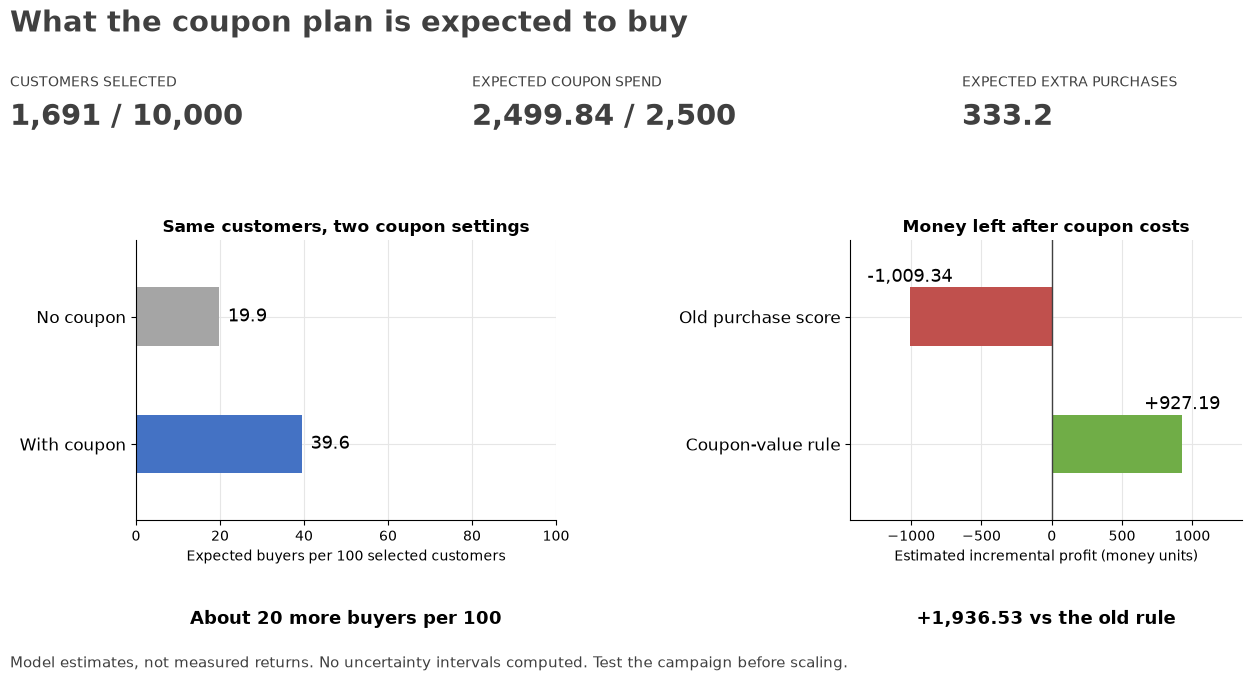

In [29]:
mu0_all, mu1_all = predict_outcomes(restored, observed)
selected_rows = chosen.to_numpy()
plot_coupon_campaign_summary(
    selected_count=int(chosen.sum()), total_customers=len(scores),
    expected_spend=float(spend), budget=GROWTH_BUDGET,
    probability_without=float(mu0_all[selected_rows].mean()) if chosen.any() else np.nan,
    probability_with=float(mu1_all[selected_rows].mean()) if chosen.any() else np.nan,
    extra_purchases=float(scores.loc[chosen, "estimated_uplift"].sum()),
    expected_profit=float(scores.loc[chosen, "expected_incremental_profit"].sum()),
    baseline_profit=float(scores.loc[old_ai.astype(bool), "expected_incremental_profit"].sum()),
)

### Recommended audience
The chart compares the actual selected lists. Higher **price sensitivity**
means greater sensitivity to price changes; higher **offer affinity** means
greater receptiveness to promotions. These and loyalty are dataset scores
from 0 to 1, not percentages of customers.

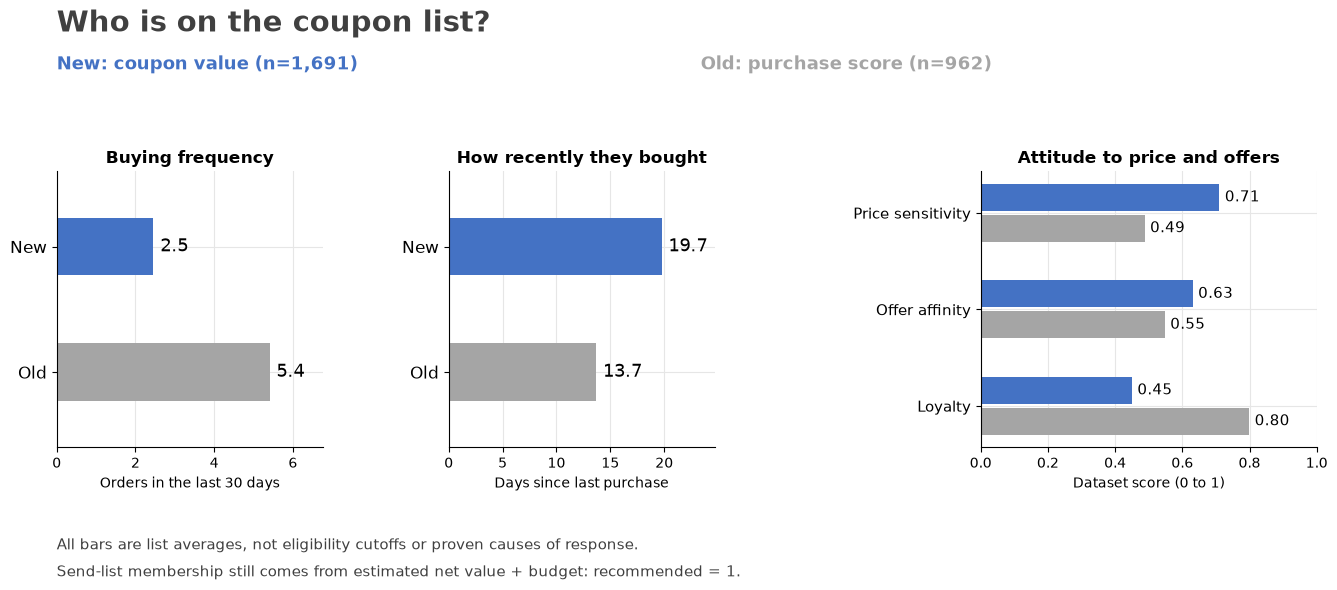

In [30]:
audience_features = [
    "orders_30d", "days_since_last_purchase", "price_sensitivity",
    "offer_affinity", "loyalty_score",
]
audience_profiles = {
    f"{'New: coupon value' if name == 'causal list' else 'Old: purchase score'} (n={mask.sum():,})":
        observed.loc[mask, audience_features].mean().to_dict()
    for name, mask in target_lists.items()
}
plot_coupon_audience(audience_profiles)

## Bottom line
**Prioritize price-sensitive, promotion-receptive occasional buyers.**
In this run, selected customers average 2-3 orders per month and last bought
about 20 days ago. The old list favors frequent, highly loyal customers.

Send coupons to `recommended=1`: their estimated added margin exceeds coupon
cost and the list fits the budget. The profile describes this list; its
averages are not eligibility cutoffs. Retain scores and models for review,
then use a randomized holdout to measure actual campaign profit.